In [31]:
import torch
from torch import nn, optim
import matplotlib.pyplot as plt

from utils import *

# Apprendre la fonction cos(x + y)

On utilise un tout petit réseau de neurones pour apprendre la fonction cos(x + y)
sur le carré $I$ discrétisé en $N^2$ points.

On compare deux optimiseurs :
- la descente de gradient ordinaire
- la descente de gradient à pas spectral

In [32]:
#torch.manual_seed(123)

I = (-4, 4)
N = 100
X = torch.linspace(*I, N)
Y = torch.linspace(*I, N)

input = torch.cartesian_prod(X, Y)
output = input.sum(dim=1).cos().reshape(-1, 1) # cos(x + y)

In [33]:
class NeuralNetwork(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()
        self.stack = nn.Sequential(
            nn.Linear(2, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, 1)
        )

    def forward(self, x):
        return self.stack(x)

names = ("SGD", "Spectral GD")
models = [NeuralNetwork(hidden_size=10) for _ in names]

spectral_params, other_params = sort_parameters(models[1].parameters())

optimizers = [
    # Model 0: SGD only
    [optim.SGD(models[0].parameters(), lr=0.08)],

    # Model 1: Spectral GD + SGD for non-matrix parameters
    [spectral_GD(param, lr=0.0017) for param in spectral_params]
    + [optim.SGD(other_params, lr=0.15)]
]

In [34]:
loss_fn = nn.MSELoss()
losses = [[] for _ in names]

epoch = 2000
for _ in range(epoch):
    for model, optimizer, loss in zip(models, optimizers, losses):
        pred = model(input)
        loss_value = loss_fn(pred, output)
        loss.append(loss_value.item())
        loss_value.backward()
        for opt in optimizer:
            opt.step()
            opt.zero_grad()

for name, loss in zip(names, losses):
    print(f"{name}: final loss = {loss[-1]:.6f}")

SGD: final loss = 0.014332
Spectral GD: final loss = 0.017038


J'ai réglé les hyperparamètres aux mieux pour les deux méthodes mais en
executant ce notebook plusieurs fois on se rend compte qu'aucune des deux
méthodes n'est généralement meilleure que l'autre. Elles produisent à tour de
rôle la meilleure approximation de la fonction objectif.

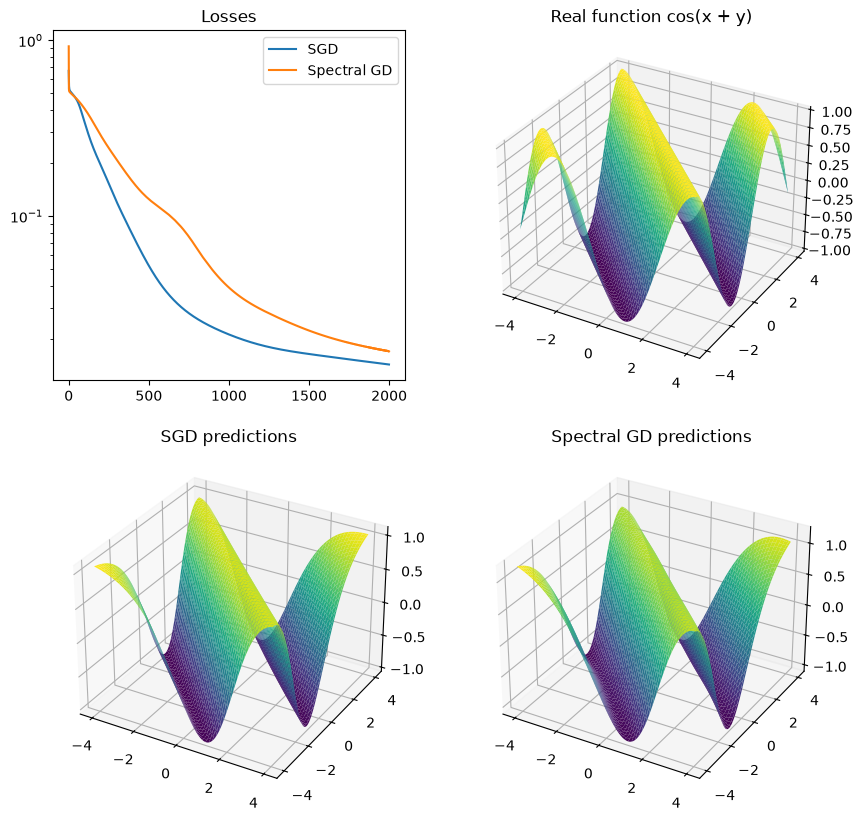

In [45]:
with torch.no_grad():
    predictions = [model(input) for model in models]

fig = plt.figure(figsize=(10, 10))

# Plotting the losses
loss_ax = fig.add_subplot(2, 2, 1)
loss_ax.set_title("Losses")
loss_ax.set_yscale('log')
for name, loss in zip(names, losses):
    loss_ax.plot(loss, label=name)
loss_ax.legend()

X_plot, Y_plot = torch.meshgrid(X, Y)

# 3D plot of the real function
real_ax = fig.add_subplot(2, 2, 2, projection='3d')
real_ax.plot_surface(X_plot, Y_plot, output.reshape(N, N), cmap='viridis')
real_ax.set_title("Real function cos(x + y)")

# 3D plots of the predictions
for i, (name, pred) in enumerate(zip(names, predictions)):
    ax = fig.add_subplot(2, 2, i + 3, projection='3d')
    ax.plot_surface(X_plot, Y_plot, pred.reshape(N, N), cmap='viridis')
    ax.set_title(f"{name} predictions")

plt.show()